# Dynamic landmark models and useful warning

**Question:** Do departures, their recent trajectories or profile×departure interactions improve future UCL warning? Compare frozen representations under the same endpoint/risk set within each horizon. 2015–2021 is training, 2022–2023 validation, and 2024–2025 previously examined exploratory transfer.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/injury_analysis').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_dynamic_common import OUT, CACHE, read_table, valid_checkpoint
pd.set_option('display.max_columns', 20)
def show(name, **kwargs):
    display(read_table(name).head(kwargs.get('rows', 30)))
def plot(name):
    display(Image(filename=str(OUT / 'figures' / (name + '.png')), width=1100))


In [2]:
from src.injury_analysis.ucl_dynamic_models import run_models
run_models()  # reuses verified checkpoints; does not refit completed models
protocol=json.loads((OUT/'frozen_protocol.json').read_text())
display({k:protocol[k] for k in ['selected_model','primary_horizon','threshold_5_percent_validation','selection_period','frozen_at_utc']})

{'selected_model': 'Departure',
 'primary_horizon': 30,
 'threshold_5_percent_validation': 0.007741912498255776,
 'selection_period': '2022–2023 validation only',
 'frozen_at_utc': '2026-10-13T04:16:46.362262+00:00'}

Fixed L2 logistic models use train-only clipping, median imputation, missingness indicators and scaling. Twelve new trajectory fields summarize four z-scores over the current and three strictly earlier-day outings within 30 days. Three interactions use training-standardized profile and departure main effects. Independent 7/14/21/30-day models are not a jointly coherent survival curve. Selection maximizes validation 7–30-day event recall at 5% budget, with AP above prevalence; ties favor fewer fields, then AP. Selection was frozen before new transfer predictions.

,partition,model,rows,positive_rows,represented_events,average_precision,pr_lift,brier_score
0,validation,Background,28875,138,25,0.007611,1.592442,0.004751
1,validation,Profile,28875,138,25,0.006115,1.279588,0.004758
2,validation,Departure,28875,138,25,0.007272,1.521611,0.004755
3,validation,Profile + departure,28875,138,25,0.007372,1.542537,0.004757
4,validation,Profile + departure + trajectory,28875,138,25,0.007692,1.609540,0.004758
5,validation,Profile + departure + trajectory + interactions,28875,138,25,0.007885,1.649954,0.004757
6,validation,Previous 62,28875,138,25,0.007849,1.642216,0.004787
7,validation,Stable 62,28875,138,25,0.010920,2.284895,0.004772
8,test,Background,29349,142,28,0.011173,2.309346,0.004814
9,test,Profile,29349,142,28,0.008081,1.670155,0.004818


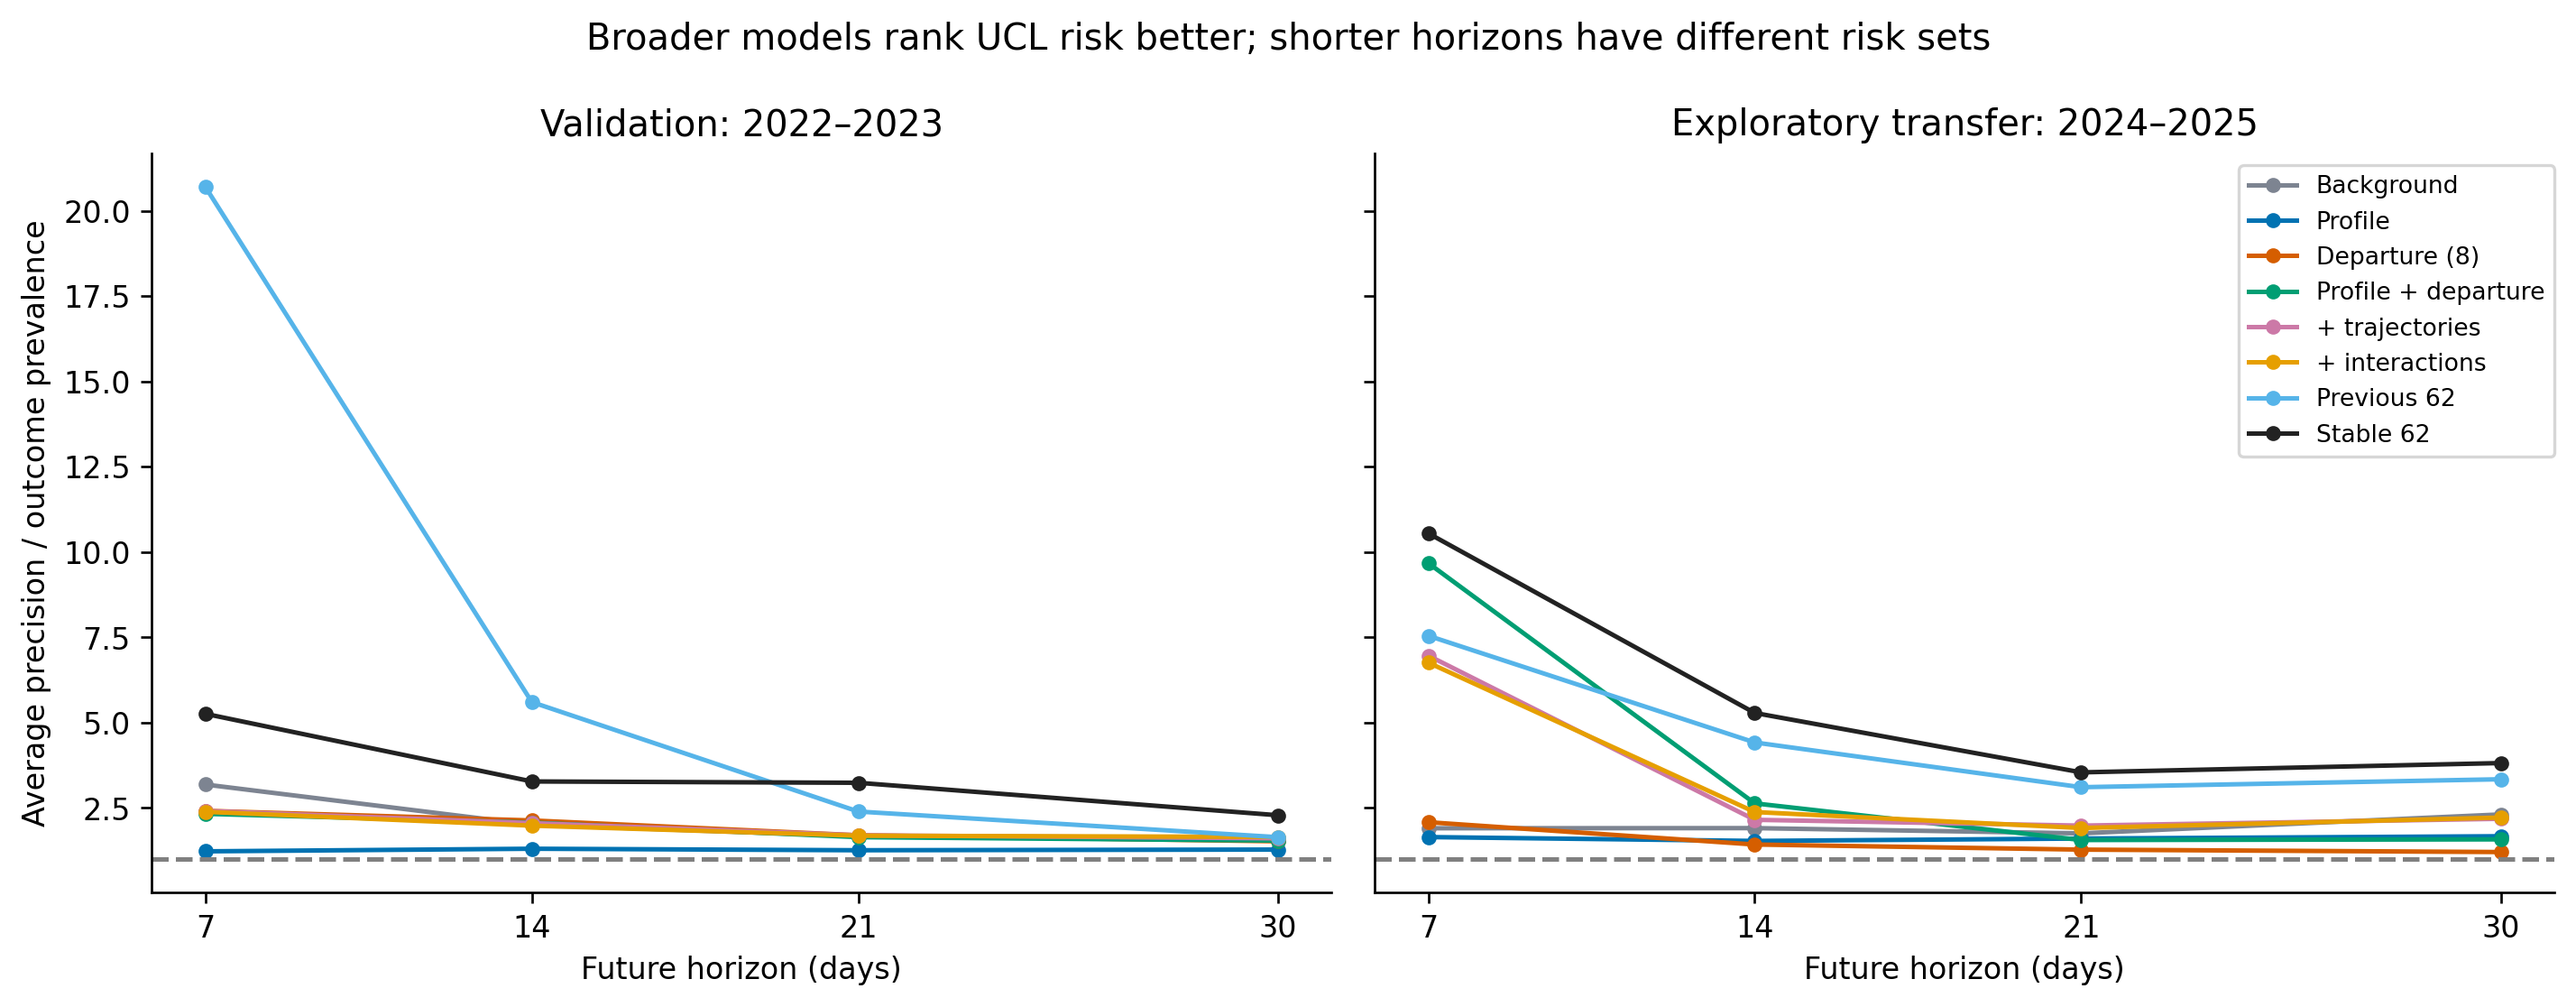

In [3]:
show('summary_model_comparison', rows=20)
plot('02_horizon_discrimination')

## Warning, rather than discrimination alone

Warning credit requires the next event be the target UCL episode, at least 7/14/21 days ahead and within 30 days. Each alert counts. Top-N budgets are retrospective; the numeric validation threshold is the future application rule. Conditional warning lead time is not a lead time for all injuries.

,partition,model,qualifying_events,observable_events,alerted_events,injury_event_recall,median_warning_lead_days,alerts,non_actionable_alert_fraction
0,validation,Background,34,20,2,0.058824,27.5,1443,0.995149
1,validation,Profile,34,20,0,0.000000,NaN,1443,1.000000
2,validation,Departure,34,20,7,0.205882,12.0,1443,0.993763
3,validation,Profile + departure,34,20,3,0.088235,12.0,1443,0.995149
4,validation,Profile + departure + trajectory,34,20,3,0.088235,12.0,1443,0.994456
5,validation,Profile + departure + trajectory + interactions,34,20,3,0.088235,12.0,1443,0.994456
6,validation,Previous 62,34,20,3,0.088235,23.0,1443,0.995149
7,validation,Stable 62,34,20,3,0.088235,15.0,1443,0.993070
8,test,Background,43,28,4,0.093023,23.0,1467,0.991138
9,test,Profile,43,28,3,0.069767,29.0,1467,0.991820


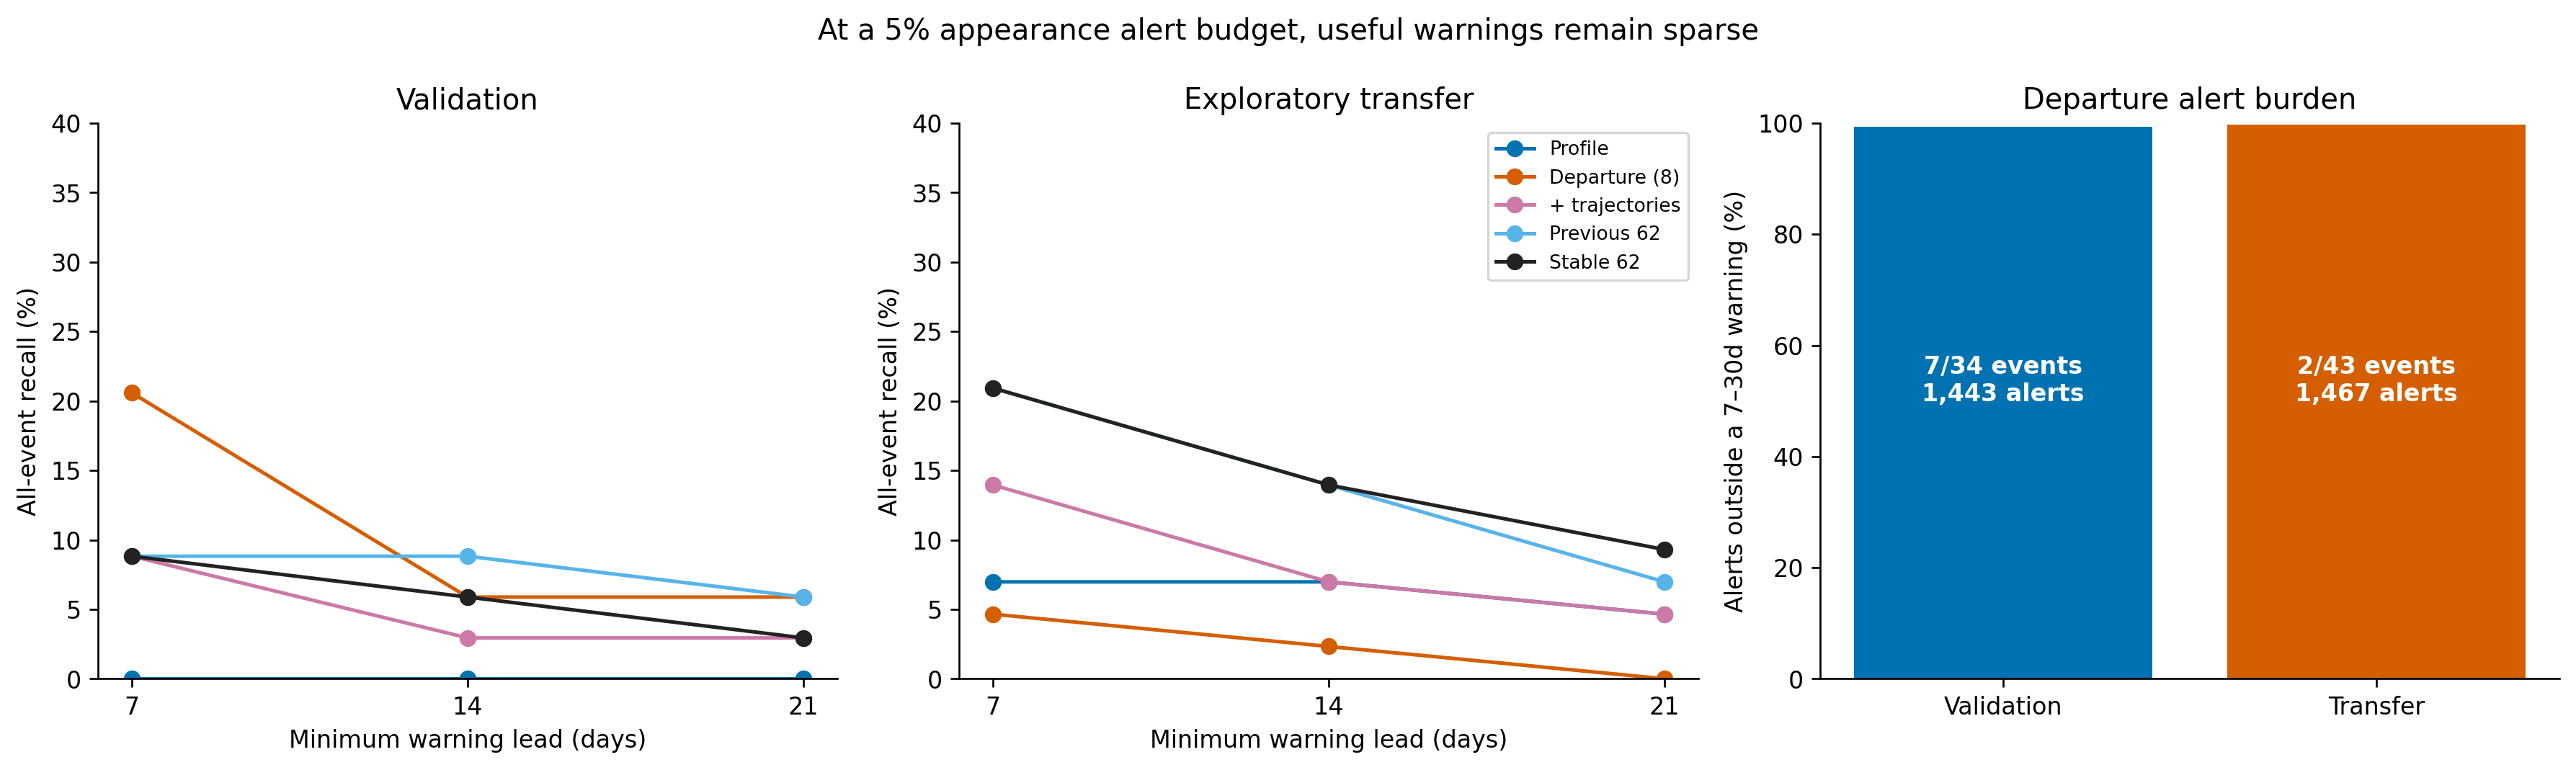

In [4]:
show('summary_warning_comparison', rows=20)
plot('03_warning_lead_and_burden')

In [5]:
w=read_table('warning_policies')
display(w.loc[w.model.eq(protocol['selected_model']),['partition','policy','minimum_lead','alerts','actual_alert_rate','alerted_events','qualifying_events','median_warning_lead_days','recall_ci_low','recall_ci_high']])

,partition,policy,minimum_lead,alerts,actual_alert_rate,alerted_events,qualifying_events,median_warning_lead_days,recall_ci_low,recall_ci_high
12,validation,retrospective_budget,7,1443,0.049974,7,34,12.0,0.088235,0.352941
13,validation,frozen_validation_threshold,7,1444,0.050009,7,34,12.0,NaN,NaN
14,validation,retrospective_budget,14,1443,0.049974,2,34,28.0,0.000000,0.147059
15,validation,frozen_validation_threshold,14,1444,0.050009,2,34,28.0,NaN,NaN
16,validation,retrospective_budget,21,1443,0.049974,2,34,28.0,0.000000,0.147059
17,validation,frozen_validation_threshold,21,1444,0.050009,2,34,28.0,NaN,NaN
60,test,retrospective_budget,7,1467,0.049985,2,43,14.0,0.000000,0.120572
61,test,frozen_validation_threshold,7,1357,0.046237,2,43,14.0,NaN,NaN
62,test,retrospective_budget,14,1467,0.049985,1,43,15.0,0.000000,0.072343
63,test,frozen_validation_threshold,14,1357,0.046237,1,43,15.0,NaN,NaN


In [6]:
show('operational_all_landmark_burden', rows=20)

,partition,model,all_prospectively_eligible_rows,alerts,actual_alert_rate,label_observed_rows,unknown_outcome_alerts,known_non_ucl_alerts,known_ucl_within_30d_alerts,qualifying_events,warned_events_7_30d,repeat_alerts_consecutive_actual_outings,two_consecutive_warning_events,two_consecutive_alert_rate,burden_note
0,validation,Departure,39725,1980,0.049843,28875,536,1428,16,34,7,370,0,0.009314,All prospectively eligible appearances; unknow...
1,validation,Profile,39725,2102,0.052914,28875,658,1442,2,34,0,1864,0,0.046923,All prospectively eligible appearances; unknow...
2,validation,Previous 62,39725,2021,0.050875,28875,577,1430,14,34,3,1101,2,0.027716,All prospectively eligible appearances; unknow...
3,validation,Stable 62,39725,1980,0.049843,28875,536,1427,17,34,3,1057,1,0.026608,All prospectively eligible appearances; unknow...
4,test,Departure,39888,1875,0.047007,29349,518,1349,8,43,2,360,1,0.009025,All prospectively eligible appearances; unknow...
5,test,Profile,39888,1630,0.040864,29349,550,1064,16,43,3,1438,3,0.036051,All prospectively eligible appearances; unknow...
6,test,Previous 62,39888,1469,0.036828,29349,444,998,27,43,8,756,4,0.018953,All prospectively eligible appearances; unknow...
7,test,Stable 62,39888,1528,0.038307,29349,458,1051,19,43,7,736,3,0.018452,All prospectively eligible appearances; unknow...


**Findings:** Departure-8 was selected by validation warning (7/34 events), but warns on only 2/43 transfer events at 5% budget. Stable-62 has the best AP among these fixed hypotheses and warns on 3/34 and 9/43; that transfer result cannot change the prior selection. Trajectories add no validation warning events over profile+departure. More than 98% of labeled departure alerts are negative for the first-event UCL outcome within 30 days, including known competing injuries. The all-landmark table also preserves unknown outcomes rather than assuming they were false alarms. No reliable prospective detector has been established.

In [7]:
show('paired_increment_uncertainty', rows=20)

,partition,comparison,metric,mean_bootstrap_difference,ci_low,ci_high,fraction_positive,interpretation
0,validation,Departure minus Profile,average_precision,0.001223,-0.002944,0.006260,0.680000,conditional on trained models; whole-pitcher r...
1,validation,Departure minus Profile,event_recall_7_30d,0.215098,0.088235,0.352941,1.000000,conditional on trained models; whole-pitcher r...
2,validation,Profile + departure minus Profile,average_precision,0.001691,-0.001623,0.007644,0.823333,conditional on trained models; whole-pitcher r...
3,validation,Profile + departure minus Profile,event_recall_7_30d,0.092353,0.000000,0.176471,0.950000,conditional on trained models; whole-pitcher r...
4,validation,Profile + departure + trajectory minus Profile...,average_precision,0.000453,-0.000858,0.002329,0.730000,conditional on trained models; whole-pitcher r...
5,validation,Profile + departure + trajectory minus Profile...,event_recall_7_30d,0.000000,0.000000,0.000000,0.000000,conditional on trained models; whole-pitcher r...
6,validation,Profile + departure + trajectory + interaction...,average_precision,0.000314,0.000017,0.001486,0.986667,conditional on trained models; whole-pitcher r...
7,validation,Profile + departure + trajectory + interaction...,event_recall_7_30d,0.000000,0.000000,0.000000,0.000000,conditional on trained models; whole-pitcher r...
8,validation,Departure minus Departure,average_precision,0.000000,0.000000,0.000000,0.000000,conditional on trained models; whole-pitcher r...
9,validation,Departure minus Departure,event_recall_7_30d,0.000000,0.000000,0.000000,0.000000,conditional on trained models; whole-pitcher r...
